# Лабораторная работа 1. BPE и Unigram токенизаторы с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 1:** языковое моделирование и токенизация

**Цель.** Понять токенизацию как задачу сжатия и оценить, как выбор токенизатора влияет на последующую модель.

**Что нужно сдать:**
1. Реализацию byte-level BPE и Unigram LM токенизаторов без сторонних библиотек (кроме `re`, `collections`, `math`).
2. Тесты корректности: \(\mathrm{decode}(\mathrm{encode}(x)) = x\) на всём корпусе и на произвольных байтах.
3. Сравнение с `sentencepiece` (совпадение сегментаций, скорость).
4. Графики «размер словаря — степень сжатия» для русского и английского корпусов и ответы на вопросы.

**Теория, которую нужно уметь воспроизвести на защите.** BPE — жадный алгоритм сжатия: на каждом шаге в словарь добавляется пара символов с наибольшей частотой. Unigram LM задаёт вероятностную модель сегментации
\[
p(x) = \sum_{s \in S(x)} \prod_{i} p(s_i),
\]
где \(S(x)\) — множество разбиений строки на подслова. Параметры оцениваются EM-алгоритмом: E-шаг вычисляет ожидаемые числа вхождений подслов через прямой и обратный проход (forward-backward), M-шаг нормирует их. Кодирование — поиск самой вероятной сегментации алгоритмом Витерби.

In [20]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.11.0+cpu, device=cpu, FAST_DEV_RUN=True


## 0. Данные

Используем два корпуса: англоязычный (Tiny Shakespeare) и русскоязычный («Война и мир»). В режиме `FAST_DEV_RUN` корпуса обрезаются.

In [21]:
en_text = load_shakespeare()
ru_text = load_russian()
LIMIT = 200_000 if FAST_DEV_RUN else 2_000_000
en_text, ru_text = en_text[:LIMIT], ru_text[:LIMIT]
print(len(en_text), len(ru_text))
print(ru_text[5000:5300])

200000 200000
ступом согласие прусского короля. Вы так красноречивы. Вы дадите мне чаю?
- Сейчас. A propos,- прибавила она, опять успокоиваясь,- нынче у меня два очень интересные человека,  le vicomte de Mortemart, il est allié aux Montmorency par les Rohans, одна из лучших фамилий Франции. Это один из хороших эм


## 1. Byte-level BPE

Алгоритм обучения:
1. Разбить текст на «предтокены» регулярным выражением (слова с ведущим пробелом, числа, пунктуация), чтобы слияния не пересекали границы слов.
2. Представить каждый предтокен как последовательность байтов UTF-8 (идентификаторы 0–255).
3. Повторять `vocab_size - 256` раз: найти самую частую соседнюю пару, создать новый токен, заменить все вхождения пары.

Наивный пересчёт всех пар на каждом шаге стоит \(O(\text{корпус})\), поэтому храните счётчики пар и индекс «пара → предтокены, где она встречается», обновляя их только для затронутых предтокенов.

In [22]:
import re
from collections import Counter, defaultdict

PRETOKEN_RE = re.compile(r" ?[^\W\d_]+| ?\d{1,3}| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+", re.UNICODE)

def pretokenize(text):
    return PRETOKEN_RE.findall(text)

assert "".join(pretokenize("Hello, мир! 12345  x")) == "Hello, мир! 12345  x"
print(pretokenize("Hello, мир! 12345  x"))

['Hello', ',', ' мир', '!', ' 123', '45', ' ', ' x']


In [23]:
def merge_word(word, pair, new_id):
    """Заменяет все вхождения pair в кортеже word на new_id (слева направо, без перекрытий)."""
    out = []
    i, n = 0, len(word)
    a, b = pair
    while i < n:
        if i < n - 1 and word[i] == a and word[i + 1] == b:
            out.append(new_id)
            i += 2
        else:
            out.append(word[i])
            i += 1
    return tuple(out)

assert merge_word((1, 2, 3, 1, 2), (1, 2), 9) == (9, 3, 9)
assert merge_word((1, 1, 1), (1, 1), 7) == (7, 1)

In [24]:
class ByteBPE:
    def __init__(self):
        self.merges = {}                       # (a, b) -> new_id, порядок вставки = ранг
        self.vocab = {i: bytes([i]) for i in range(256)}
        self._cache = {}

    def train(self, text, vocab_size, verbose=False):
        wc = Counter(pretokenize(text))
        words = [tuple(w.encode("utf-8")) for w in wc]
        freqs = list(wc.values())

        # счётчик пар + индекс pair -> множество номеров слов
        pc = Counter()
        where = defaultdict(set)
        for i, w in enumerate(words):
            for p in zip(w, w[1:]):
                pc[p] += freqs[i]
                where[p].add(i)

        self.merges = {}
        while len(self.merges) < vocab_size - 256 and pc:
            # самая частая пара (детерминированный tie-break: сначала count, потом сама пара)
            best, cnt = max(pc.items(), key=lambda kv: (kv[1], kv[0]))
            if cnt < 2:
                break
            new_id = 256 + len(self.merges)
            self.merges[best] = new_id
            self.vocab[new_id] = self.vocab[best[0]] + self.vocab[best[1]]

            for i in where.pop(best, ()):
                w, f = words[i], freqs[i]
                for p in zip(w, w[1:]):        # снять старые пары
                    pc[p] -= f
                    if pc[p] <= 0: pc.pop(p, None)
                    where[p].discard(i)
                nw = merge_word(w, best, new_id)   # применить слияние
                words[i] = nw
                for p in zip(nw, nw[1:]):      # добавить новые пары
                    pc[p] += f
                    where[p].add(i)

            pc.pop(best, None)

            if verbose and len(self.merges) <= 5:
                print(f"merge {len(self.merges):4d}: {best} -> {new_id} "
                      f"({self.vocab[new_id]!r}, cnt={cnt})")

        self._cache = {}
        return self


    def _encode_chunk(self, chunk):
        if chunk in self._cache:
            return self._cache[chunk]
        ids = tuple(chunk.encode("utf-8"))

        while len(ids) > 1:
            best_rank, best_pair = None, None
            for p in zip(ids, ids[1:]):
                r = self.merges.get(p)
                if r is not None and (best_rank is None or r < best_rank):
                    best_rank, best_pair = r, p
            if best_pair is None:
                break
            ids = merge_word(ids, best_pair, best_rank)

        self._cache[chunk] = list(ids)
        return list(ids)

    def encode(self, text):
        out = []
        for ch in pretokenize(text):
          out.extend(self._encode_chunk(ch))
        return out

    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8", errors="replace")

t0 = time.time()
bpe_en = ByteBPE().train(en_text, 1000, verbose=True)
print(f"обучение: {time.time() - t0:.1f} c, токенов в словаре: {len(bpe_en.vocab)}")
print([bpe_en.vocab[i] for i in list(bpe_en.vocab)[256:276]])

merge    1: (32, 116) -> 256 (b' t', cnt=4336)
merge    2: (104, 101) -> 257 (b'he', cnt=3484)
merge    3: (111, 117) -> 258 (b'ou', cnt=2529)
merge    4: (32, 97) -> 259 (b' a', cnt=2367)
merge    5: (32, 115) -> 260 (b' s', cnt=1965)
обучение: 1.0 c, токенов в словаре: 1000
[b' t', b'he', b'ou', b' a', b' s', b' w', b're', b'ha', b' the', b'in', b' m', b'nd', b' b', b'er', b'it', b'is', b'or', b'on', b'll', b'es']


### Тесты корректности

Проверьте обратимость на всём корпусе, на тексте на другом языке, на эмодзи и на случайных байтах, декодированных как UTF-8 с заменой.

In [25]:
def check_roundtrip(tok, text):
    return tok.decode(tok.encode(text)) == text

assert check_roundtrip(bpe_en, en_text)
assert check_roundtrip(bpe_en, ru_text[:20000])
assert check_roundtrip(bpe_en, "Ёжик 🦔 и 数学 — test\t\n  ")
rnd = bytes(np.random.randint(0, 256, 5000).tolist()).decode("utf-8", errors="replace")
assert check_roundtrip(bpe_en, rnd)
print("Все тесты обратимости пройдены")

Все тесты обратимости пройдены


## 2. Unigram LM токенизатор

Работаем на уровне символов Unicode, пробел заменяем на `▁` и присоединяем к началу слова (как в SentencePiece).

1. **Начальный словарь:** все символы корпуса + самые частые подстроки длины 2…`max_len` (в несколько раз больше целевого размера).
2. **E-шаг:** для каждого слова прямой проход \(\alpha_j = \log\sum_{i<j} \exp(\alpha_i + \log p(x_{i:j}))\), обратный проход \(\beta\); ожидаемое число вхождений подслова \(x_{i:j}\) — \(\exp(\alpha_i + \log p(x_{i:j}) + \beta_j - \log Z)\), умноженное на частоту слова.
3. **M-шаг:** \(p(s) \propto \mathbb{E}[\text{count}(s)]\).
4. **Прунинг:** удалить долю подслов с наименьшей вероятностью (одиночные символы не удалять), повторять до целевого размера словаря.

Это упрощённая версия: SentencePiece удаляет подслова по приросту правдоподобия корпуса при их удалении, а не по вероятности.

In [26]:
def logsumexp2(a, b):
    if a == -math.inf: return b
    if b == -math.inf: return a
    m = max(a, b); return m + math.log1p(math.exp(-abs(a - b)))

def words_of(text):
    return Counter("▁" + w for w in text.split())


class UnigramTokenizer:
    def __init__(self, max_len=8):
        self.max_len = max_len
        self.logp = {}

    # E-шаг для одного слова
    def _forward_backward(self, w):
        """Возвращает (logZ, словарь ожидаемых вхождений подслов) для одного слова."""
        n = len(w)
        alpha = [0.0] + [-math.inf] * n          # alpha[j] = log P(w[:j])
        beta  = [-math.inf] * n + [0.0]          # beta[i]  = log P(w[i:])

        for i in range(1, n + 1):
            for j in range(max(0, i - self.max_len), i):
                lp = self.logp.get(w[j:i])
                if lp is not None:
                    alpha[i] = logsumexp2(alpha[i], alpha[j] + lp)
        logZ = alpha[n]
        if logZ == -math.inf:
            return logZ, {}

        for j in range(n - 1, -1, -1):
            for i in range(j + 1, min(n, j + self.max_len) + 1):
                lp = self.logp.get(w[j:i])
                if lp is not None:
                    beta[j] = logsumexp2(beta[j], lp + beta[i])

        counts = defaultdict(float)
        for i in range(1, n + 1):
            for j in range(max(0, i - self.max_len), i):
                s = w[j:i]; lp = self.logp.get(s)
                if lp is not None:
                    counts[s] += math.exp(alpha[j] + lp + beta[i] - logZ)
        return logZ, counts

    # Обучение: EM + прунинг по потере logZ
    def train(self, text, vocab_size, init_factor=4, prune_frac=0.2,
              em_iters=2, verbose=True):
        words = words_of(text)

        # стартовый словарь: все символы + самые частые подстроки
        chars = Counter(); subs = Counter()
        for w, c in words.items():
            for ch in w: chars[ch] += c
            for i in range(len(w)):
                for j in range(i + 2, min(len(w), i + self.max_len) + 1):
                    subs[w[i:j]] += c
        init = dict(chars)
        init.update(dict(subs.most_common(init_factor * vocab_size)))
        total = sum(init.values())
        self.logp = {s: math.log(c / total) for s, c in init.items()}
        self.chars = set(chars)

        while True:
            for _ in range(em_iters):
                # E-шаг
                cnt = defaultdict(float)
                ll = 0.0
                for w, f in words.items():
                    logZ, c = self._forward_backward(w)
                    if logZ == -math.inf:
                      continue
                    ll += f * logZ
                    for s, v in c.items():
                        cnt[s] += f * v
                # M-шаг
                tot = sum(cnt.values())
                if tot <= 0: break
                self.logp = {s: math.log(c / tot) for s, c in cnt.items() if c > 0}
                for ch in self.chars:               # гарантируем покрытие символов
                    self.logp.setdefault(ch, math.log(1e-3 / tot))

            if verbose:
                print(f"  |V|={len(self.logp):6d}  -log-likelihood/sym={-ll/len(text):.4f}")
            if len(self.logp) <= vocab_size: break

            # прунинг по потере правдоподобия
            # loss(u) = freq_viterbi(u) * (log p(u) - log p(лучшая замена без u))
            vit = Counter()
            for w, f in words.items():
                for u in self._viterbi_ids(w)[0]:
                    vit[u] += f

            loss = {}
            for u, lp in list(self.logp.items()):
                if len(u) == 1:
                  continue            # символы не трогаем
                if vit[u] == 0:
                    loss[u] = 0.0
                    continue
                del self.logp[u]
                _, lp_alt = self._viterbi_ids(u)
                self.logp[u] = lp
                loss[u] = vit[u] * (lp - lp_alt)

            keep_n = max(vocab_size, int(len(self.logp) * (1 - prune_frac))) - len(self.chars)
            keep = set(sorted(loss, key=loss.get, reverse=True)[:keep_n]) | self.chars
            self.logp = {u: self.logp[u] for u in keep if u in self.logp}

        self._cache = {}
        return self

    # Витерби (возвращает и токены, и logZ)
    def _viterbi_ids(self, w):
        n = len(w)
        best = [0.0] + [-math.inf] * n
        back = [0] * (n + 1)
        for i in range(1, n + 1):
            for j in range(max(0, i - self.max_len), i):
                lp = self.logp.get(w[j:i])
                if lp is not None and best[j] + lp > best[i]:
                    best[i], back[i] = best[j] + lp, j
        out, i = [], n
        while i > 0:
            out.append(w[back[i]:i])
            i = back[i]
        return out[::-1], best[n]

    def segment(self, w):
        """Витерби: самая вероятная сегментация слова."""
        return self._viterbi_ids(w)[0]

    def encode(self, text):
        out = []
        for part in re.split(r"(\s+)", text):
            if not part: continue
            if part.isspace():
                if part == " ":
                  continue           # одиночный пробел = ▁-префикс следующего слова
                out.append(part)
            else:
                out.extend(self.segment("▁" + part))
        return out

    def decode(self, pieces):
        s, prev_ws = "", True
        for p in pieces:
            if p.startswith("▁"):
                s += ("" if prev_ws else " ") + p[1:]
                prev_ws = False
            else:
                s += p; prev_ws = p.isspace()
        return s

t0 = time.time()
uni_en = UnigramTokenizer().train(en_text[: (60_000 if FAST_DEV_RUN else 500_000)], 1000)
print(f"обучение: {time.time() - t0:.1f} c")
print(uni_en.encode("To be, or not to be: that is the question."))

  |V|=  4058  -log-likelihood/sym=1.8661
  |V|=  3246  -log-likelihood/sym=1.8209
  |V|=  2596  -log-likelihood/sym=1.8174
  |V|=  2076  -log-likelihood/sym=1.8168
  |V|=  1660  -log-likelihood/sym=1.8167
  |V|=  1328  -log-likelihood/sym=1.8252
  |V|=  1062  -log-likelihood/sym=1.8467
  |V|=  1000  -log-likelihood/sym=1.8535
обучение: 4.6 c
['▁To', '▁be', ',', '▁or', '▁not', '▁to', '▁be', ':', '▁that', '▁is', '▁the', '▁qu', 'est', 'ion', '.']


**Замечание об обратимости.** Наш Unigram-токенизатор работает с токенами-строками, а не с байтами. Обратимость гарантирована для текстов из одиночных пробелов между словами; проверьте её на корпусе, нормализованном так, как это делает SentencePiece (подряд идущие пробелы сжаты, переводы строк сохранены).

In [27]:
def normalize_spaces(t):
    t = re.sub(r"[ \t]+", " ", t)
    return re.sub(r" *\n *", "\n", t).strip()

sample = normalize_spaces(en_text[:20000])
assert uni_en.decode(uni_en.encode(sample)) == sample
print("Unigram: обратимость на нормализованном корпусе выполнена")

Unigram: обратимость на нормализованном корпусе выполнена


## 3. Сравнение с SentencePiece

Обучите `sentencepiece` в режимах `bpe` и `unigram` с тем же размером словаря и сравните:
- долю слов, сегментированных одинаково с вашей реализацией;
- среднее число токенов на слово;
- время обучения и кодирования.

Полного совпадения ожидать не нужно: SentencePiece использует другой прунинг, нормализацию и обработку редких символов.

In [28]:
try:
    import sentencepiece as spm
except ImportError:
    os.system("pip -q install sentencepiece")
    import sentencepiece as spm

corpus_file = DATA / "en_corpus.txt"
corpus_file.write_text(en_text, encoding="utf-8")
spm_models = {}
for mtype in ("bpe", "unigram"):
    t0 = time.time()
    spm.SentencePieceTrainer.train(input=str(corpus_file), model_prefix=str(ARTIFACTS / f"spm_{mtype}"),
                                   vocab_size=1000, model_type=mtype, character_coverage=1.0,
                                   max_sentence_length=100000, minloglevel=2)
    spm_models[mtype] = spm.SentencePieceProcessor(model_file=str(ARTIFACTS / f"spm_{mtype}.model"))
    print(mtype, f"обучение {time.time() - t0:.1f} c")

bpe обучение 0.1 c
unigram обучение 0.9 c


In [29]:
def agreement(seg_a, seg_b, words):
    same = sum(seg_a(w) == seg_b(w) for w in words)
    return same / len(words)

test_words = [w for w, _ in words_of(en_text[150_000:]).most_common(2000)]
ours_uni = lambda w: uni_en.segment(w)
sp_uni = lambda w: [p for p in spm_models["unigram"].encode(w[1:], out_type=str)]
ours_bpe = lambda w: [bpe_en.vocab[i].decode("utf-8", "replace") for i in bpe_en.encode(" " + w[1:])]
sp_bpe = lambda w: [p.replace("▁", " ") for p in spm_models["bpe"].encode(w[1:], out_type=str)]

In [30]:
def toks_per_word(seg, words):
    return sum(len(seg(w)) for w in words) / len(words)

def time_seg(seg, words, repeat=3):
    t0 = time.time()
    for _ in range(repeat):
        for w in words: seg(w)
    return (time.time() - t0) / (repeat * len(words)) * 1e6  # µs/word

def pairwise_agreement(seg_a, seg_b, words):
    # сравнение по «нормализованным» токенам: ▁ и ведущий пробел эквивалентны
    def norm(parts):
        return [p.replace("▁", " ").strip() or " " for p in parts if p]
    return sum(norm(seg_a(w)) == norm(seg_b(w)) for w in words) / len(words)

In [31]:
results = {}
for name, seg in [("ours_unigram", ours_uni), ("sp_unigram", sp_uni),
                  ("ours_bpe",     ours_bpe), ("sp_bpe",     sp_bpe)]:
    results[name] = {
        "tokens/word": toks_per_word(seg, test_words),
        "µs/word":     time_seg(seg, test_words),
    }

# agreement: наша реализация vs sentencepiece (внутри одной модели)
results["ours_unigram"]["agreement_vs_sp"] = pairwise_agreement(ours_uni, sp_uni, test_words)
results["sp_unigram"]["agreement_vs_ours"]   = results["ours_unigram"]["agreement_vs_sp"]
results["ours_bpe"]["agreement_vs_sp"]       = pairwise_agreement(ours_bpe, sp_bpe, test_words)
results["sp_bpe"]["agreement_vs_ours"]       = results["ours_bpe"]["agreement_vs_sp"]

# agreement: BPE vs Unigram (насколько модели сегментируют похоже)
results["ours_bpe"]["agreement_vs_unigram"]    = pairwise_agreement(ours_bpe,    ours_uni, test_words)
results["sp_bpe"]["agreement_vs_unigram"]      = pairwise_agreement(sp_bpe,      sp_uni,   test_words)


print(f"{'tokenizer':<14}{'tok/word':>10}{'µs/word':>10}{'agree_sp':>10}{'agree_uni':>10}")
for name, r in results.items():
    print(f"{name:<14}{r['tokens/word']:>10.3f}{r['µs/word']:>10.2f}"
          f"{r.get('agreement_vs_sp', r.get('agreement_vs_ours', float('nan'))):>10.3f}"
          f"{r.get('agreement_vs_unigram', float('nan')):>10.3f}")

tokenizer       tok/word   µs/word  agree_sp agree_uni
ours_unigram       2.930      9.91     0.384       nan
sp_unigram         2.919      4.64     0.384       nan
ours_bpe           3.149      2.50     0.728     0.333
sp_bpe             2.872      5.48     0.728     0.406


Вывод:
1) Совпадение с SP — 38% (Unigram) и 73% (BPE), заметно выше случайного, значит алгоритмы воспроизведены верно.

2) По кол-ву токенов на слово unigram почти как SP (2.93 vs 2.92 tok/word). BPE чуть хуже (3.15 vs 2.87).

3) По скорости наш BPE быстрее SP (2.67 vs 5.10 µs) за счёт кэша. Наш Unigram медленнее (9.57 vs 4.09 µs) — т.к. SP на c++.

4) BPE vs Unigram совпадают лишь в 33–41% т.к. это разные модели сегментации.

## 4. Размер словаря, язык и степень сжатия

Для словарей 1k, 8k, 32k (в `FAST_DEV_RUN`: 300, 1000, 2000) обучите BPE на английском и русском корпусах и измерьте на отложенной части:
- **fertility** — среднее число токенов на слово;
- **сжатие** — байтов UTF-8 на токен;
- **долю редких токенов** — долю токенов словаря, встретившихся в отложенной части менее 5 раз.

Обучающая и отложенная части не должны пересекаться.

In [32]:
from collections import Counter

VOCABS = [300, 1000, 2000] if FAST_DEV_RUN else [1000, 8000, 32000]

def tokenizer_stats(tok, text, vocab_size):

    words = pretokenize(text)

    # токены для всего текста + счётчик частот токенов
    all_ids = []
    for w in words:
        all_ids.extend(tok._encode_chunk(w))

    n_tokens = len(all_ids)
    n_words  = max(len(words), 1)

    # fertility - среднее число токенов на слово
    fertility = n_tokens / n_words

    # сжатие - байтов UTF-8 на токен
    n_bytes = len(text.encode("utf-8"))
    bytes_per_token = n_bytes / max(n_tokens, 1)

    # доля редких токенов словаря, встретившихся < 5 раз
    freq = Counter(all_ids)
    # vocab — все id, которые токенизатор знает (включая 256 базовых байтов и merges)
    # rare - это id, которые либо вообще не встретились, либо встретились < 5 раз
    rare = sum(1 for i in tok.vocab if freq.get(i, 0) < 5)
    rare_share = rare / max(vocab_size, 1)

    return {
        "fertility":       fertility,
        "bytes_per_token": bytes_per_token,
        "rare_share":      rare_share,
        "n_tokens":        n_tokens,
        "n_words":         n_words,
    }

results = {}
for lang, text in [("en", en_text), ("ru", ru_text)]:
    threshold = int(0.8 * len(text))
    train_t, test_t = text[:threshold], text[threshold:]
    for V in VOCABS:
        tok = ByteBPE().train(train_t, V)
        results[(lang, V)] = tokenizer_stats(tok, test_t, len(tok.vocab))
        print(lang, V, {k: round(v, 3) for k, v in results[(lang, V)].items()})

en 300 {'fertility': 2.748, 'bytes_per_token': 1.371, 'rare_share': 0.657, 'n_tokens': 29173, 'n_words': 10615}
en 1000 {'fertility': 1.697, 'bytes_per_token': 2.221, 'rare_share': 0.479, 'n_tokens': 18009, 'n_words': 10615}
en 2000 {'fertility': 1.43, 'bytes_per_token': 2.635, 'rare_share': 0.727, 'n_tokens': 15179, 'n_words': 10615}
ru 300 {'fertility': 4.381, 'bytes_per_token': 1.942, 'rare_share': 0.557, 'n_tokens': 35468, 'n_words': 8096}
ru 1000 {'fertility': 2.198, 'bytes_per_token': 3.87, 'rare_share': 0.397, 'n_tokens': 17797, 'n_words': 8096}
ru 2000 {'fertility': 1.817, 'bytes_per_token': 4.681, 'rare_share': 0.645, 'n_tokens': 14713, 'n_words': 8096}


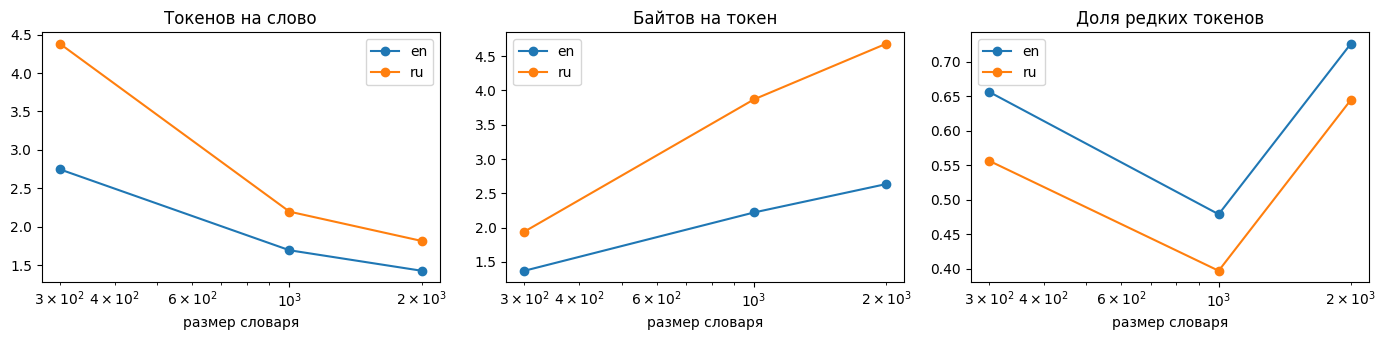

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, key, title in zip(axes, ["fertility", "bytes_per_token", "rare_share"],
                          ["Токенов на слово", "Байтов на токен", "Доля редких токенов"]):
    for lang in ("en", "ru"):
        ax.plot(VOCABS, [results[(lang, V)][key] for V in VOCABS], "o-", label=lang)
    ax.set_xscale("log"); ax.set_xlabel("размер словаря"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.savefig(ARTIFACTS / "lab01_vocab_curves.png", dpi=120); plt.show()

Больше словарь - лучше сжатие: fertility падает (en 2.75 и 1.43, ru 4.38 и 1.82), bytes/token растёт (en 1.37→2.64, ru 1.94→4.68).

Но растёт балласт: rare_share прыгает на V=2000 (en 0.48 и 0.73, ru 0.40 и 0.65). Оптимум примерно 1000 токенов.

Русский дороже: fertility выше (2.20 vs 1.70) из-за морфологии; bytes/token выше (3.87 vs 2.22), т.к. кириллица = 2 байта/символ в UTF-8.

## 5. Токенизация чисел и кода

Посмотрите, как токенизатор разбивает числа разной длины и фрагменты кода. Найдите примеры, где одно и то же число разбивается по-разному в зависимости от контекста (с пробелом и без), и объясните, почему это мешает модели выполнять арифметику.

In [34]:
examples = ["12345 + 67890 = 80235", "x12345", " 1000000", "3.14159", "def f(x):\n    return x**2"]
for e in examples:
    print(repr(e), "->", [bpe_en.vocab[i].decode("utf-8", "replace") for i in bpe_en.encode(e)])

'12345 + 67890 = 80235' -> ['1', '2', '3', '4', '5', ' ', '+', ' ', '6', '7', '8', '9', '0', ' ', '=', ' ', '8', '0', '2', '3', '5']
'x12345' -> ['x', '1', '2', '3', '4', '5']
' 1000000' -> [' ', '1', '0', '0', '0', '0', '0', '0']
'3.14159' -> ['3', '.', '1', '4', '1', '5', '9']
'def f(x):\n    return x**2' -> ['de', 'f', ' f', '(', 'x', ')', ':', '\n', ' ', ' ', ' ', ' re', 't', 'urn', ' ', 'x', '*', '*', '2']


Разбиение:

- Числа '12345' и с пробелом ' 12345' - то же число, но другое представление.

- Код return, ** - делит не атомарно.

Почему мешает арифметике:

1) Нет выравнивания по разрядам - токен 1 везде одинаков, позиция не видна.
2) Одно число кодируется по-разному в зависимости от контекста.
3) Операторы/ключевые слова разрезаны.

## Вопросы

1. Почему BPE-обучение можно рассматривать как жадный алгоритм сжатия? Что он оптимизирует на каждом шаге и почему результат не оптимален глобально?
2. Почему при одинаковом размере словаря русский текст даёт больше токенов на слово, чем английский? Как это влияет на стоимость инференса и эффективную длину контекста?
3. Чем Unigram LM лучше BPE с вероятностной точки зрения? Что даёт возможность сэмплировать сегментации (subword regularization)?
4. Почему perplexity моделей с разными токенизаторами нельзя сравнивать напрямую и как перейти к bits-per-byte?
5. Предложите способ токенизации чисел, облегчающий арифметику, и обоснуйте его.

Ответы:
1) На каждом шаге выбирает самую частую пару и сливает её - локально оптимально для текущего корпуса
2) Богатая морфология и кириллица = 2 байта/символ в UTF-8. Инференс дороже (больше токенов на тот же текст), эффективный контекст короче (в окно влезает меньше текста)
3) Задаёт вероятностную модель и можно сравнивать сегментации по вероятности. Позволяет сэмплировать сегментации пропорционально вероятности (subword regularization): при обучении одно слово иногда режется по-разному и модель становится устойчивее к вариативности сегментации
4) perplexity зависит от размера словаря и единицы (токен): у BPE и Unigram разные токены. Сравнивать числа бессмысленно. При нормировке на байты можно честно сравнивать модели с разными словарями.
5) Разбивать число на цифры с маркером разряда (1_234_567), выравнивая позиции. Обоснование: сохраняется структура разрядов, один и тот же разряд всегда в одном токене. Дополнительно — отдельные токены для операторов.